# 07 — Reusable raw-to-results pipeline
One saved parent, fixed held-out queries, verified nested prefixes, and three backends. Heavy work runs in fresh worker processes through `chemtellect.raw_pipeline`. Historical notebooks are never executed or edited. Default mode only verifies and displays saved reports.

## Configuration

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from chemtellect.raw_pipeline import run_pipeline, load_pipeline, read_json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/chemtellect").is_dir())
MODE = "load"  # "execute" starts/resumes the explicit experiment below
CONFIG = ROOT / "experiments/configs/chemicalspace_new_scale_1m_pipeline.json"
EXPERIMENT = ROOT / "experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333"
AUDIT = ROOT / "experiments/results/raw_pipeline/acquisition_audit"
pd.set_option("display.precision", 8)
print("Mode:", MODE, "\nExperiment:", EXPERIMENT)

Mode: load 
Experiment: /home/ruben/Coding Projects/chemtellect/experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333


## Audit and staged execution
Execute mode checks raw integrity/chemistry, computes all-eligible descriptors, freezes the deterministic split, prepares the full approved fingerprint artifact, and runs each size sequentially. Load mode never runs searches. Logs and completion status distinguish failed gates from successful benchmarks.

In [2]:
if MODE == "execute":
    run_pipeline(ROOT, CONFIG, directory=EXPERIMENT, audit_path=AUDIT)
elif MODE != "load":
    raise ValueError("MODE must be execute or load")
state, audit, reports = load_pipeline(ROOT, EXPERIMENT)
display(pd.Series(audit["counts"], name="Records").to_frame())
print("Status:", state["status"], "\nEligibility:", state.get("eligibility"))
print("Raw SHA-256:", audit["sha256"])
if state["blockers"]: display(state["blockers"])

Your CPU supports instructions that this binary was not compiled to use: SSE3 SSE4.1 SSE4.2 AVX AVX2
For maximum performance, you can install NMSLIB from sources 
pip install --no-binary :all: nmslib


,Records
total_input_records,1010000
successfully_parsed_records,1009919
invalid_molecular_records,81
integrity_rejected_records,0
unique_canonical_structures,1009693
duplicate_structure_groups,225
records_in_duplicate_groups,451
surplus_duplicate_records,226


Status: complete 
Eligibility: {'required': 1000100, 'eligible': 1009693, 'deficit': 0, 'passed': True}
Raw SHA-256: c1b109f02bb58378d253a2e7f68f2a994c6269d90a73c241f882cc1e8856c297


## Split
Canonical-disjoint 100-query holdout, seed 42 identity-hash ordering, and explicitly registered index prefixes. The largest index defines selected/unused counts. No parent is manufactured if eligibility fails.

In [3]:
display(state["stages"].get("split", "NOT CREATED"))
if "descriptors" in state["stages"]:
    print("All-eligible descriptor rows:", state["stages"]["descriptors"]["rows"])
    display(pd.DataFrame(state["stages"]["descriptors"]["summary"]).T)

{'file': {'bytes': 222105415,
  'sha256': 'd285c83a812e32c8c454f42c4845bad88c4ab9d5f2cca8a7909fb8bcf44ddde0'},
 'index_sizes': [1000, 10000, 100000, 1000000],
 'query_count': 100,
 'selected_count': 1000100,
 'split_id': '17cc63bd0df36cbc162e424afaaf6b44a7384df3b20cd2eac2f36477d3ee004b',
 'split_path': 'experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333/parent_split.json',
 'stage_wall_ns': 26181102437,
 'unused_count': 9593,
 'unused_records_file': {'bytes': 2130900,
  'sha256': 'e6929e72f51721fb5b65c7629543ce47ba6f7d39595b47f4ddc0dd26f25e0697'}}

All-eligible descriptor rows: 1009693


,maximum,mean,minimum
heavy_atoms,152.0000,22.06406304,3.0000
logp,26.7528,2.70005274,-9.1137
molecular_weight,2082.6640,323.83326839,56.0680
rotatable_bonds,36.0000,4.96233509,0.0000
tpsa,518.7200,63.32248412,0.0000


## Fingerprints
Approved Morgan radius 2 / 2048 bits / chirality configuration in full; canonical SMILES input, little packed-bit convention, verified split and RDKit linkage, and nonzero checks across all selected rows. Fingerprint collisions retain distinct structure IDs.

In [4]:
display(state["stages"].get("fingerprints", "NOT PREPARED"))

{'artifact_id': '56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0',
 'artifact_path': 'data/processed/chemicalspace_new/scale_1m_00/fingerprints/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0',
 'nonzero_validation': {'index_rows_checked': 1000000,
  'index_zero_rows': 0,
  'policy_identifier': 'nonzero_fingerprints_v1',
  'query_rows_checked': 100,
  'query_zero_rows': 0},
 'operation': 'generated',
 'report_path': 'experiments/results/fingerprints/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/run_54b457be8b44496698e8a2a49cefcb08.json',
 'stage_wall_ns': 236346066982}

## Compatibility
The existing combined runner creates fresh authoritative RDKit scores and runs synthetic plus real-data gates before timing. FPSim2 must match exact tie-aware membership. HNSW approximation loss is measured as recall; native score tolerance never changes membership.

In [5]:
from chemtellect.hnsw_reporting import tables
for report in reports:
    print(f"Index {report["index_size"]:,}; run {report["run_id"]}")
    display(tables(report)["Correctness"])

Index 1,000; run 1bf039f5e38b4d2c931436ddbe375105


,Status,Passed responses,Failed responses
Gate,,,
Synthetic HNSW,PASS,12,0
Synthetic FPSim2,PASS,16,0
Real FPSim2,PASS,800,0
Real HNSW,PASS,400,0
Measured rdkit,PASS,2000,0
Measured fpsim2,PASS,2000,0
Measured hnsw,PASS,2000,0


Index 10,000; run 190d7d9129134c00b4f303c8dd708a76


,Status,Passed responses,Failed responses
Gate,,,
Synthetic HNSW,PASS,12,0
Synthetic FPSim2,PASS,16,0
Real FPSim2,PASS,800,0
Real HNSW,PASS,400,0
Measured rdkit,PASS,2000,0
Measured fpsim2,PASS,2000,0
Measured hnsw,PASS,2000,0


Index 100,000; run c34c30febc044b49a053b77fff688c72


,Status,Passed responses,Failed responses
Gate,,,
Synthetic HNSW,PASS,12,0
Synthetic FPSim2,PASS,16,0
Real FPSim2,PASS,800,0
Real HNSW,PASS,400,0
Measured rdkit,PASS,2000,0
Measured fpsim2,PASS,2000,0
Measured hnsw,PASS,2000,0


Index 1,000,000; run ea2725c6bba24a8986eb54e24d1c76ba


,Status,Passed responses,Failed responses
Gate,,,
Synthetic HNSW,PASS,12,0
Synthetic FPSim2,PASS,16,0
Real FPSim2,PASS,800,0
Real HNSW,PASS,400,0
Measured rdkit,PASS,2000,0
Measured fpsim2,PASS,2000,0
Measured hnsw,PASS,2000,0


## Benchmark execution evidence
One warmup plus five measured passes per k, 100 queries, sequential searches, seeded orders and rotating backends. Each completed size has 6,000 measured searches and 1,200 warmups, plus preflight calls. RDKit recomputes all similarities in every timed request. Reloading this notebook in load mode does not benchmark.

In [6]:
display(pd.DataFrame([{ "index_size": int(n), **{k: saved.get(k) for k in ("run_id", "status", "measured_searches", "warmup_searches", "loader_verified", "path")} } for n, saved in state["sizes"].items()]))
for report in reports:
    print(f"Index {report["index_size"]:,}")
    frames = tables(report)
    for label in ("Sequential latency", "Tie-aware top-k recall", "Top-k-limited threshold recall", "Preparation and costs", "Memory snapshots (not peaks)"):
        display(Markdown("### " + label))
        display(frames[label])

,index_size,run_id,status,measured_searches,warmup_searches,loader_verified,path
0,1000,1bf039f5e38b4d2c931436ddbe375105,complete,6000,1200,True,experiments/results/hnsw/chemicalspace_new/sca...
1,10000,190d7d9129134c00b4f303c8dd708a76,complete,6000,1200,True,experiments/results/hnsw/chemicalspace_new/sca...
2,100000,c34c30febc044b49a053b77fff688c72,complete,6000,1200,True,experiments/results/hnsw/chemicalspace_new/sca...
3,1000000,ea2725c6bba24a8986eb54e24d1c76ba,complete,6000,1200,True,experiments/results/hnsw/chemicalspace_new/sca...


Index 1,000


### Sequential latency

,,Scoring / search median (µs),Selection / normalization median (µs),Total median (µs),Total mean (µs),p95 of per-query median latency (µs),Time saved vs RDKit (µs),Speedup vs RDKit (×),Speedup vs FPSim2 (×)
Backend,k,,,,,,,,
rdkit,10,95.8970,41.5855,138.0830,139.02756,144.15450,0.0000,1.00000000,0.54446601
fpsim2,10,62.4860,12.4405,75.1815,76.38835,82.46600,62.9015,1.83666194,1.00000000
hnsw,10,423.0485,11.6450,434.6490,436.62582,468.90850,-296.5660,0.31768853,0.17297060
rdkit,25,97.7365,42.5560,140.8125,142.16536,147.60850,0.0000,1.00000000,0.60027341
fpsim2,25,67.5715,16.4155,84.5260,85.60961,90.73350,56.2865,1.66590753,1.00000000
hnsw,25,423.1885,15.4355,438.9940,437.71146,457.34850,-298.1815,0.32076179,0.19254477
rdkit,50,100.7870,44.0710,145.8025,148.95969,154.50350,0.0000,1.00000000,0.67129850
fpsim2,50,73.6020,24.5060,97.8770,99.32920,108.29650,47.9255,1.48965028,1.00000000
hnsw,50,425.4680,22.8100,448.6140,447.63556,471.25350,-302.8115,0.32500658,0.21817643


### Tie-aware top-k recall

,,mean,median,minimum,query_count
Backend,k,,,,
rdkit,10,1.0,1.0,1.0,100
fpsim2,10,1.0,1.0,1.0,100
hnsw,10,1.0,1.0,1.0,100
rdkit,25,1.0,1.0,1.0,100
fpsim2,25,1.0,1.0,1.0,100
hnsw,25,1.0,1.0,1.0,100
rdkit,50,1.0,1.0,1.0,100
fpsim2,50,1.0,1.0,1.0,100
hnsw,50,1.0,1.0,1.0,100


... (35 outputs left out)

### Preparation and costs

,Elapsed (ms)
Stage,
designated recall and latency comparison evaluation,9.83343464e+03
fpsim2 conversion database loading and verification,3.69530755e+04
fresh exhaustive reference computation and validation,1.61449131e+04
full artifact loading integrity verification and selection,9.76569581e+03
hnsw graph and data saving,2.29209023e+03
plotting,7.64813228e+02
prepared query persistence,1.70748600e+00
raw hash and count verification,2.11351473e+02
rdkit index reconstruction,7.30080824e+03


### Memory snapshots (not peaks)

,UTC,Total system RAM (GiB),Available system RAM (GiB),Process RSS (MiB)
Stage,,,,
before_loading,2026-11-12T03:53:17.038051+00:00,15.03766632,10.53193283,154.34375000
verified_and_guarded_inputs,2026-11-12T03:53:34.474682+00:00,15.03766632,9.70857620,1117.99218750
rdkit_and_fresh_reference_prepared,2026-11-12T03:53:59.929722+00:00,15.03766632,9.70424271,2193.73046875
fpsim2_prepared,2026-11-12T03:54:36.919177+00:00,15.03766632,9.29569244,2510.26562500
fresh_hnsw_graph_built,2026-11-12T04:28:28.856971+00:00,15.03766632,8.72415924,3238.96875000
after_gate_and_optional_comparative_passes,2026-11-12T04:37:07.858212+00:00,15.03766632,8.20594788,3603.05468750


## Reporting
Standalone Markdown, CSV tables, per-query recall/threshold evidence, stage costs, and PNG/SVG charts are saved externally. Latency is the median/mean/linear p95 across the 100 per-query five-pass medians. No confidence interval or combined speed-quality score is claimed. Resource snapshots are not peaks.

Verified report: /home/ruben/Coding Projects/chemtellect/experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333/report_4c7de786bde745a5b33bf8e3eef42f1c/report.md


# chemicalspace_new/scale_1m_00

Status: **complete**. Requested sizes: [1000, 10000, 100000, 1000000].

Raw SHA-256: `c1b109f02bb58378d253a2e7f68f2a994c6269d90a73c241f882cc1e8856c297`. RDKit: 2026.09.1.

Canonical sanitized isomeric SMILES; no standardization; first physical representative.


## Acquisition and selection

- total_input_records: 1,010,000

- successfully_parsed_records: 1,009,919

- invalid_molecular_records: 81

- integrity_rejected_records: 0

- unique_canonical_structures: 1,009,693

- duplicate_structure_groups: 225

- records_in_duplicate_groups: 451

- surplus_duplicate_records: 226

- Eligibility gate: {'required': 1000100, 'eligible': 1009693, 'deficit': 0, 'passed': True}

- Audit and full findings: `experiments/results/raw_pipeline/acquisition_audit/audit.json` (IDs and lines for chemical exclusions).

- `findings.csv` resolves chemical exclusions and all duplicate group members to source IDs and physical lines; `eligible.jsonl` retains each first physical representative.

- Split: {'file': {'bytes': 222105415, 'sha256': 'd285c83a812e32c8c454f42c4845bad88c4ab9d5f2cca8a7909fb8bcf44ddde0'}, 'index_sizes': [1000, 10000, 100000, 1000000], 'query_count': 100, 'selected_count': 1000100, 'split_id': '17cc63bd0df36cbc162e424afaaf6b44a7384df3b20cd2eac2f36477d3ee004b', 'split_path': 'experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333/parent_split.json', 'stage_wall_ns': 26181102437, 'unused_count': 9593, 'unused_records_file': {'bytes': 2130900, 'sha256': 'e6929e72f51721fb5b65c7629543ce47ba6f7d39595b47f4ddc0dd26f25e0697'}}

- Fingerprints: {'artifact_id': '56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0', 'artifact_path': 'data/processed/chemicalspace_new/scale_1m_00/fingerprints/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0', 'nonzero_validation': {'index_rows_checked': 1000000, 'index_zero_rows': 0, 'policy_identifier': 'nonzero_fingerprints_v1', 'query_rows_checked': 100, 'query_zero_rows': 0}, 'operation': 'generated', 'report_path': 'experiments/results/fingerprints/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/run_54b457be8b44496698e8a2a49cefcb08.json', 'stage_wall_ns': 236346066982}


## Measured comparisons

Latencies are µs: median, mean and linear p95 across 100 per-query five-pass medians. One warmup plus five measured passes per k; k=10/25/50/100; thresholds=.3/.5/.7/.9. Speedup is a ratio of headline medians. Component medians need not add to the total.

No confidence interval was estimated; repetitions share queries and one graph.

Preparation implementation note: the first three sizes used NumPy scalar-to-string NMSLIB encoding; 1M used an exhaustive byte lookup producing identical 4,095-character strings. Conversion costs therefore reflect this disclosed optimization. Native graph construction, prepared query values, timed searches and scientific configurations are unchanged.


### 1,000 index rows

Run `1bf039f5e38b4d2c931436ddbe375105`: `experiments/results/hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000/run_1bf039f5e38b4d2c931436ddbe375105`.

All synthetic and real preflight gates PASS; 6,000 measured and 1,200 warmup searches. Loader verified.

At k=10, fpsim2 has the lowest measured headline median (75.181 µs, 1.837× RDKit). HNSW loses 0.000000 percentage points of mean tie-aware recall; its worst query recall is 1.00000000.

At k=25, fpsim2 has the lowest measured headline median (84.526 µs, 1.666× RDKit). HNSW loses 0.000000 percentage points of mean tie-aware recall; its worst query recall is 1.00000000.

At k=50, fpsim2 has the lowest measured headline median (97.877 µs, 1.490× RDKit). HNSW loses 0.000000 percentage points of mean tie-aware recall; its worst query recall is 1.00000000.

At k=100, fpsim2 has the lowest measured headline median (123.537 µs, 1.252× RDKit). HNSW loses 0.000000 percentage points of mean tie-aware recall; its worst query recall is 1.00000000.

- rdkit k=10: median 138.083 µs; mean 139.028; p95 144.155; 1.000× RDKit, 0.544× FPSim2; saved 0.000/-62.901 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=10: median 75.181 µs; mean 76.388; p95 82.466; 1.837× RDKit, 1.000× FPSim2; saved 62.901/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=10: median 434.649 µs; mean 436.626; p95 468.909; 0.318× RDKit, 0.173× FPSim2; saved -296.566/-359.467 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- rdkit k=25: median 140.812 µs; mean 142.165; p95 147.608; 1.000× RDKit, 0.600× FPSim2; saved 0.000/-56.286 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=25: median 84.526 µs; mean 85.610; p95 90.733; 1.666× RDKit, 1.000× FPSim2; saved 56.286/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=25: median 438.994 µs; mean 437.711; p95 457.349; 0.321× RDKit, 0.193× FPSim2; saved -298.182/-354.468 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- rdkit k=50: median 145.803 µs; mean 148.960; p95 154.504; 1.000× RDKit, 0.671× FPSim2; saved 0.000/-47.925 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=50: median 97.877 µs; mean 99.329; p95 108.296; 1.490× RDKit, 1.000× FPSim2; saved 47.925/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=50: median 448.614 µs; mean 447.636; p95 471.253; 0.325× RDKit, 0.218× FPSim2; saved -302.812/-350.737 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- rdkit k=100: median 154.633 µs; mean 159.981; p95 203.004; 1.000× RDKit, 0.799× FPSim2; saved 0.000/-31.096 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=100: median 123.537 µs; mean 124.746; p95 138.577; 1.252× RDKit, 1.000× FPSim2; saved 31.096/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=100: median 463.894 µs; mean 465.311; p95 492.841; 0.333× RDKit, 0.266× FPSim2; saved -309.261/-340.356 µs; tie-aware recall mean 1.00000000, min 1.00000000.





### 10,000 index rows

Run `190d7d9129134c00b4f303c8dd708a76`: `experiments/results/hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_10000/run_190d7d9129134c00b4f303c8dd708a76`.

All synthetic and real preflight gates PASS; 6,000 measured and 1,200 warmup searches. Loader verified.

At k=10, fpsim2 has the lowest measured headline median (273.905 µs, 4.239× RDKit). HNSW loses 0.200000 percentage points of mean tie-aware recall; its worst query recall is 0.90000000.

At k=25, fpsim2 has the lowest measured headline median (285.745 µs, 4.060× RDKit). HNSW loses 0.360000 percentage points of mean tie-aware recall; its worst query recall is 0.96000000.

At k=50, fpsim2 has the lowest measured headline median (314.627 µs, 4.213× RDKit). HNSW loses 0.400000 percentage points of mean tie-aware recall; its worst query recall is 0.96000000.

At k=100, fpsim2 has the lowest measured headline median (366.042 µs, 3.791× RDKit). HNSW loses 0.730000 percentage points of mean tie-aware recall; its worst query recall is 0.95000000.

- rdkit k=10: median 1161.058 µs; mean 1201.608; p95 1357.203; 1.000× RDKit, 0.236× FPSim2; saved 0.000/-887.153 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=10: median 273.905 µs; mean 277.881; p95 297.666; 4.239× RDKit, 1.000× FPSim2; saved 887.153/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=10: median 850.212 µs; mean 856.230; p95 1065.184; 1.366× RDKit, 0.322× FPSim2; saved 310.846/-576.307 µs; tie-aware recall mean 0.99800000, min 0.90000000.

- rdkit k=25: median 1160.248 µs; mean 1186.985; p95 1372.961; 1.000× RDKit, 0.246× FPSim2; saved 0.000/-874.503 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=25: median 285.745 µs; mean 287.577; p95 296.763; 4.060× RDKit, 1.000× FPSim2; saved 874.503/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=25: median 861.533 µs; mean 870.117; p95 1068.086; 1.347× RDKit, 0.332× FPSim2; saved 298.716/-575.787 µs; tie-aware recall mean 0.99640000, min 0.96000000.

- rdkit k=50: median 1325.611 µs; mean 1384.345; p95 1669.847; 1.000× RDKit, 0.237× FPSim2; saved 0.000/-1010.984 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=50: median 314.627 µs; mean 321.978; p95 389.010; 4.213× RDKit, 1.000× FPSim2; saved 1010.984/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=50: median 978.384 µs; mean 983.234; p95 1185.116; 1.355× RDKit, 0.322× FPSim2; saved 347.227/-663.757 µs; tie-aware recall mean 0.99600000, min 0.96000000.

- rdkit k=100: median 1387.787 µs; mean 1410.803; p95 1682.461; 1.000× RDKit, 0.264× FPSim2; saved 0.000/-1021.745 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=100: median 366.042 µs; mean 382.764; p95 466.863; 3.791× RDKit, 1.000× FPSim2; saved 1021.745/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=100: median 1008.995 µs; mean 1017.945; p95 1259.507; 1.375× RDKit, 0.363× FPSim2; saved 378.793/-642.953 µs; tie-aware recall mean 0.99270000, min 0.95000000.





### 100,000 index rows

Run `c34c30febc044b49a053b77fff688c72`: `experiments/results/hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_100000/run_c34c30febc044b49a053b77fff688c72`.

All synthetic and real preflight gates PASS; 6,000 measured and 1,200 warmup searches. Loader verified.

At k=10, hnsw has the lowest measured headline median (1493.814 µs, 8.828× RDKit). HNSW loses 0.800000 percentage points of mean tie-aware recall; its worst query recall is 0.90000000.

At k=25, hnsw has the lowest measured headline median (1768.205 µs, 8.289× RDKit). HNSW loses 1.040000 percentage points of mean tie-aware recall; its worst query recall is 0.88000000.

At k=50, hnsw has the lowest measured headline median (1495.324 µs, 9.214× RDKit). HNSW loses 1.180000 percentage points of mean tie-aware recall; its worst query recall is 0.92000000.

At k=100, hnsw has the lowest measured headline median (1548.791 µs, 8.731× RDKit). HNSW loses 2.240000 percentage points of mean tie-aware recall; its worst query recall is 0.86000000.

- rdkit k=10: median 13187.634 µs; mean 13426.868; p95 14726.780; 1.000× RDKit, 0.292× FPSim2; saved 0.000/-9336.209 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=10: median 3851.425 µs; mean 3855.767; p95 4657.702; 3.424× RDKit, 1.000× FPSim2; saved 9336.209/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=10: median 1493.814 µs; mean 1487.475; p95 1775.349; 8.828× RDKit, 2.578× FPSim2; saved 11693.819/2357.611 µs; tie-aware recall mean 0.99200000, min 0.90000000.

- rdkit k=25: median 14655.993 µs; mean 14790.752; p95 16619.745; 1.000× RDKit, 0.318× FPSim2; saved 0.000/-10001.921 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=25: median 4654.072 µs; mean 4710.660; p95 5960.340; 3.149× RDKit, 1.000× FPSim2; saved 10001.921/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=25: median 1768.205 µs; mean 1759.834; p95 2198.120; 8.289× RDKit, 2.632× FPSim2; saved 12887.788/2885.867 µs; tie-aware recall mean 0.98960000, min 0.88000000.

- rdkit k=50: median 13777.320 µs; mean 13784.840; p95 15232.645; 1.000× RDKit, 0.260× FPSim2; saved 0.000/-10198.915 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=50: median 3578.405 µs; mean 3951.242; p95 5209.595; 3.850× RDKit, 1.000× FPSim2; saved 10198.915/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=50: median 1495.324 µs; mean 1573.415; p95 2072.573; 9.214× RDKit, 2.393× FPSim2; saved 12281.996/2083.081 µs; tie-aware recall mean 0.98820000, min 0.92000000.

- rdkit k=100: median 13523.186 µs; mean 13685.841; p95 15302.085; 1.000× RDKit, 0.260× FPSim2; saved 0.000/-10011.743 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=100: median 3511.443 µs; mean 3923.710; p95 5254.608; 3.851× RDKit, 1.000× FPSim2; saved 10011.743/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=100: median 1548.791 µs; mean 1575.277; p95 2041.559; 8.731× RDKit, 2.267× FPSim2; saved 11974.396/1962.653 µs; tie-aware recall mean 0.97760000, min 0.86000000.





### 1,000,000 index rows

Run `ea2725c6bba24a8986eb54e24d1c76ba`: `experiments/results/hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000000/run_ea2725c6bba24a8986eb54e24d1c76ba`.

All synthetic and real preflight gates PASS; 6,000 measured and 1,200 warmup searches. Loader verified.

At k=10, hnsw has the lowest measured headline median (1719.111 µs, 78.263× RDKit). HNSW loses 2.600000 percentage points of mean tie-aware recall; its worst query recall is 0.20000000.

At k=25, hnsw has the lowest measured headline median (1772.926 µs, 76.914× RDKit). HNSW loses 2.440000 percentage points of mean tie-aware recall; its worst query recall is 0.16000000.

At k=50, hnsw has the lowest measured headline median (1809.162 µs, 75.437× RDKit). HNSW loses 2.620000 percentage points of mean tie-aware recall; its worst query recall is 0.12000000.

At k=100, hnsw has the lowest measured headline median (1803.937 µs, 73.799× RDKit). HNSW loses 3.340000 percentage points of mean tie-aware recall; its worst query recall is 0.15000000.

- rdkit k=10: median 134542.827 µs; mean 134585.785; p95 139834.295; 1.000× RDKit, 0.278× FPSim2; saved 0.000/-97096.230 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=10: median 37446.597 µs; mean 37684.560; p95 41234.356; 3.593× RDKit, 1.000× FPSim2; saved 97096.230/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=10: median 1719.111 µs; mean 1710.582; p95 2093.619; 78.263× RDKit, 21.783× FPSim2; saved 132823.717/35727.486 µs; tie-aware recall mean 0.97400000, min 0.20000000.

- rdkit k=25: median 136363.584 µs; mean 136293.223; p95 140354.251; 1.000× RDKit, 0.277× FPSim2; saved 0.000/-98635.976 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=25: median 37727.607 µs; mean 37895.420; p95 40669.583; 3.614× RDKit, 1.000× FPSim2; saved 98635.976/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=25: median 1772.926 µs; mean 1770.661; p95 2192.720; 76.914× RDKit, 21.280× FPSim2; saved 134590.658/35954.681 µs; tie-aware recall mean 0.97560000, min 0.16000000.

- rdkit k=50: median 136477.054 µs; mean 136949.069; p95 140780.984; 1.000× RDKit, 0.280× FPSim2; saved 0.000/-98214.860 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=50: median 38262.195 µs; mean 38403.455; p95 41932.911; 3.567× RDKit, 1.000× FPSim2; saved 98214.860/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=50: median 1809.162 µs; mean 1810.871; p95 2177.290; 75.437× RDKit, 21.149× FPSim2; saved 134667.892/36453.033 µs; tie-aware recall mean 0.97380000, min 0.12000000.

- rdkit k=100: median 133128.997 µs; mean 133255.090; p95 136413.551; 1.000× RDKit, 0.286× FPSim2; saved 0.000/-95078.623 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- fpsim2 k=100: median 38050.374 µs; mean 38099.839; p95 40566.626; 3.499× RDKit, 1.000× FPSim2; saved 95078.623/0.000 µs; tie-aware recall mean 1.00000000, min 1.00000000.

- hnsw k=100: median 1803.937 µs; mean 1820.442; p95 2192.508; 73.799× RDKit, 21.093× FPSim2; saved 131325.060/36246.437 µs; tie-aware recall mean 0.96660000, min 0.15000000.














## Resource observations and costs

See resources.csv and per-size memory/cost CSVs. RSS and available RAM are snapshots, not peaks. Resource estimates are planning envelopes, not observations. Worker wall times include loader/persistence overhead where measured; checksumming/publication and controller/report overhead are not all individually timed.


## Blockers

None.


## Limitations

One acquisition, 100 fixed held-out queries, one graph at each size, machine-specific sequential in-memory performance and uncontrolled scheduling/cache effects. No measured 100M claim or biological validity claim. Quality measures agreement with exact Tanimoto in the approved representation. Threshold recall excludes empty ground truth and is limited by k; per-query qualifying counts and denominators are retained. Historical acquisitions are separate. Speed and quality have no combined score.

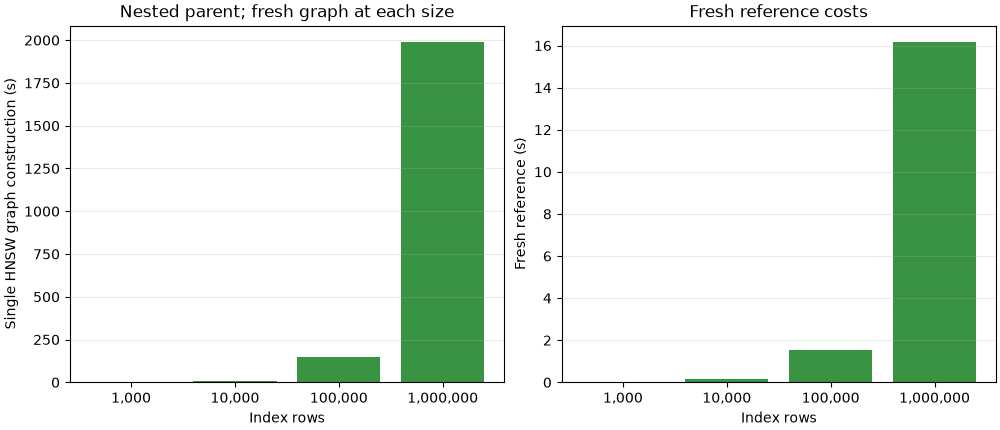

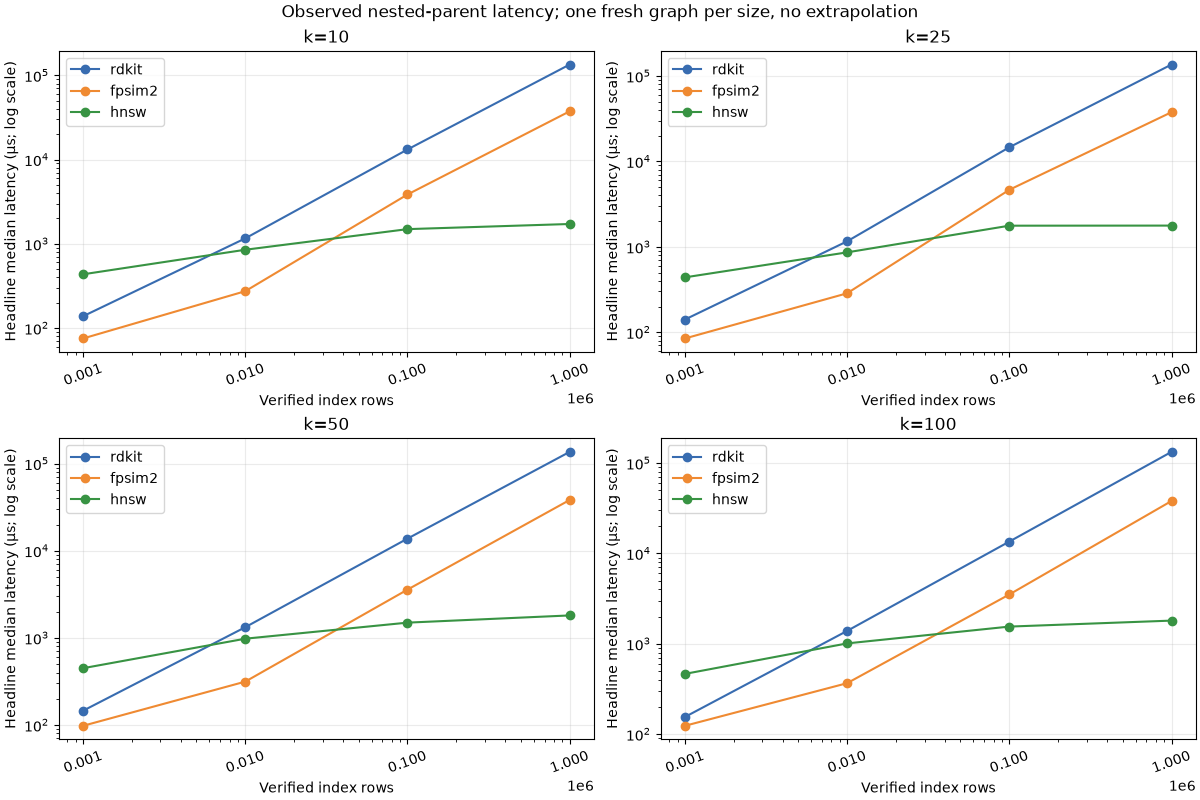

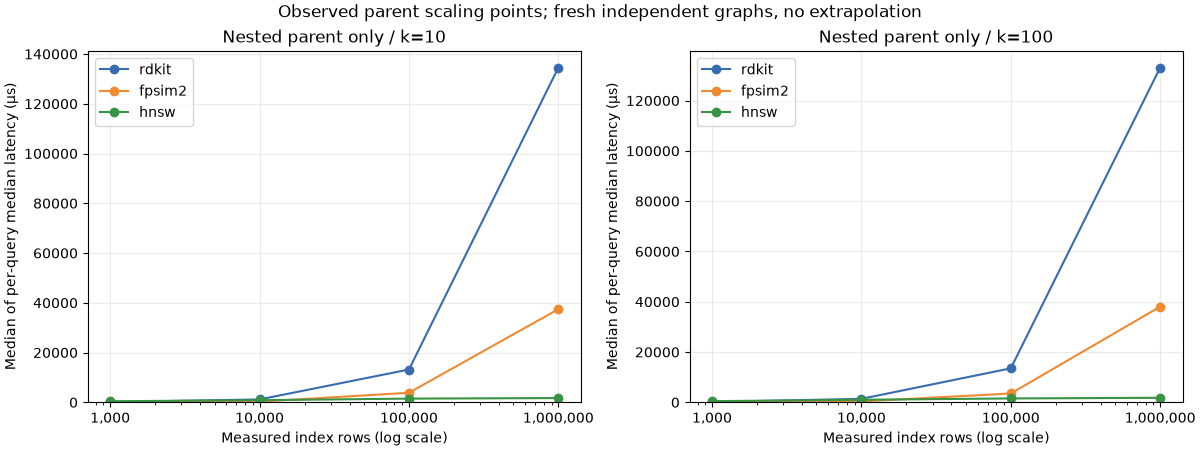

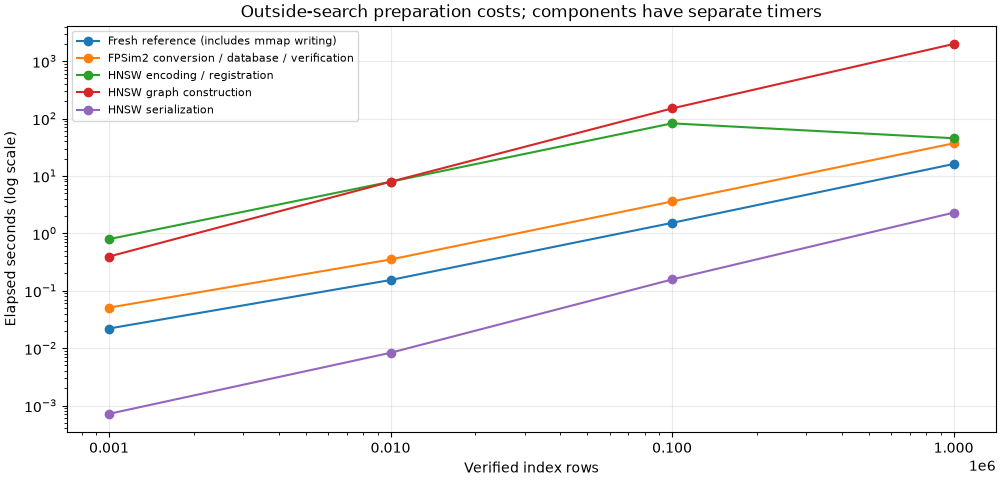

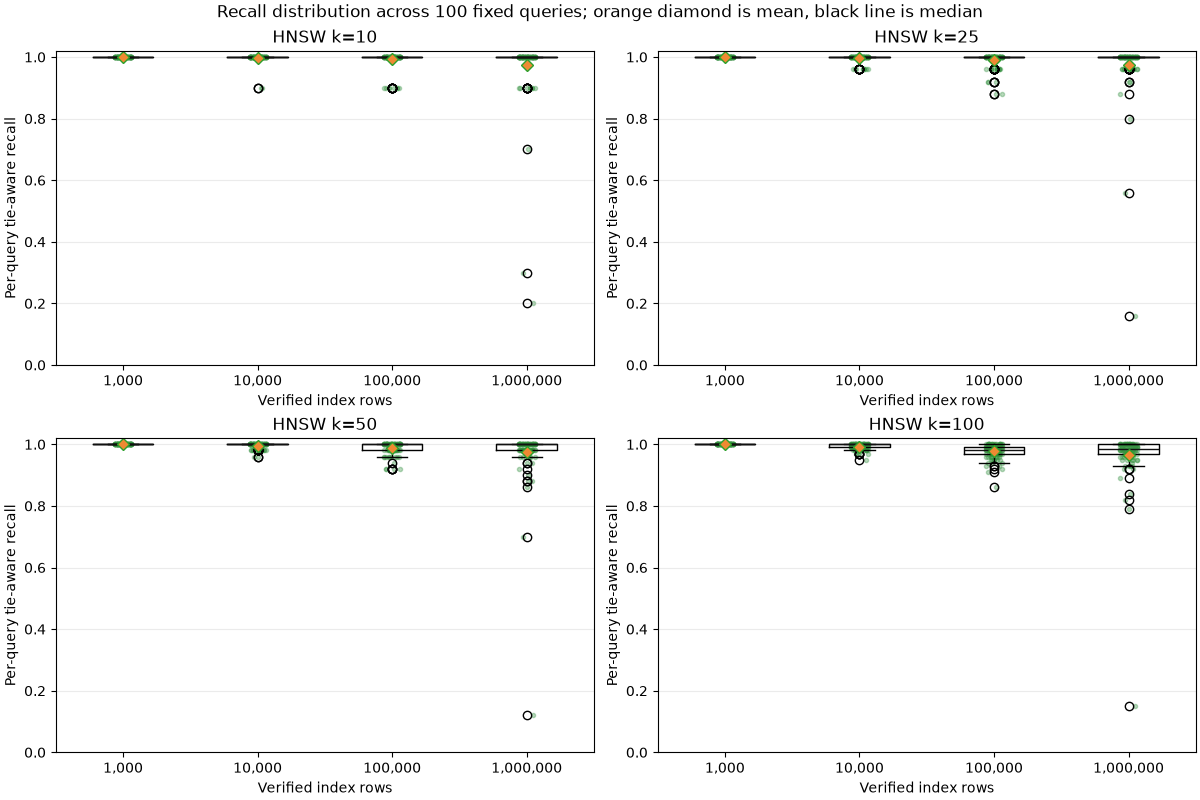

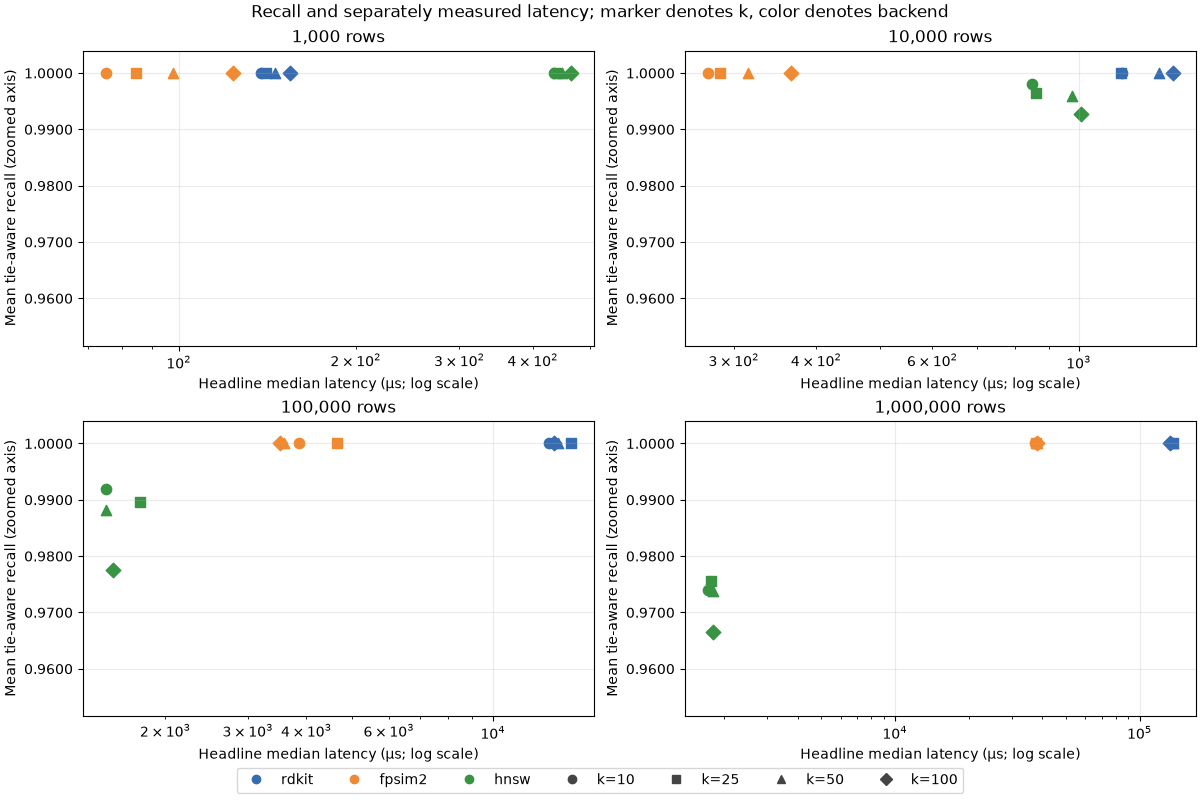

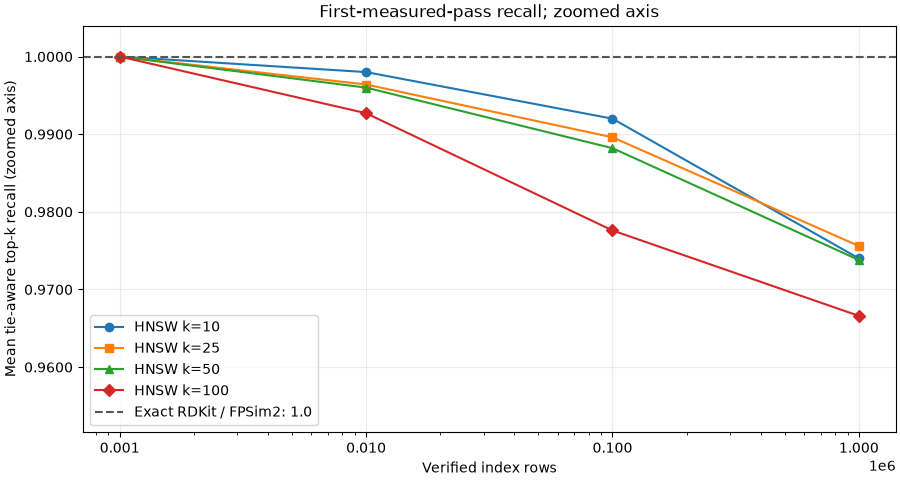

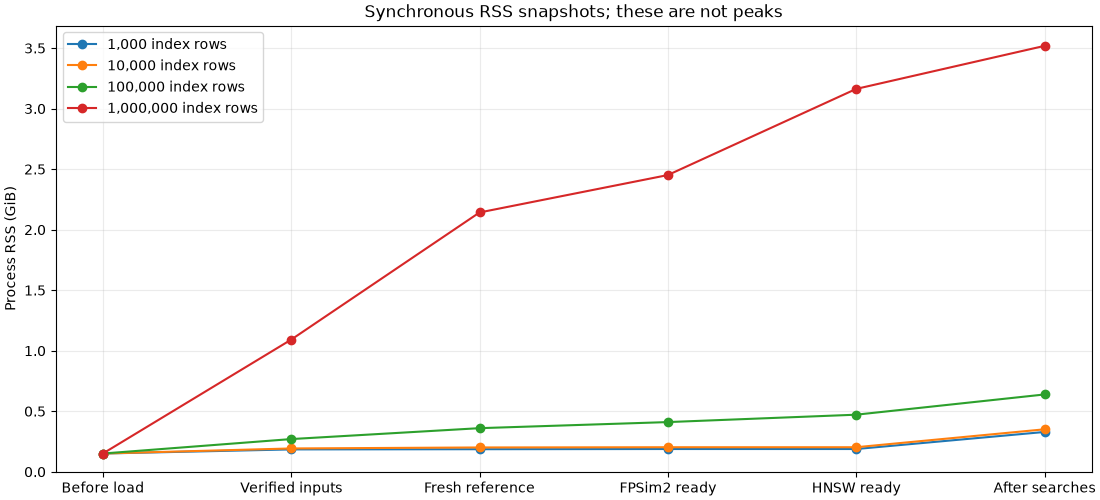

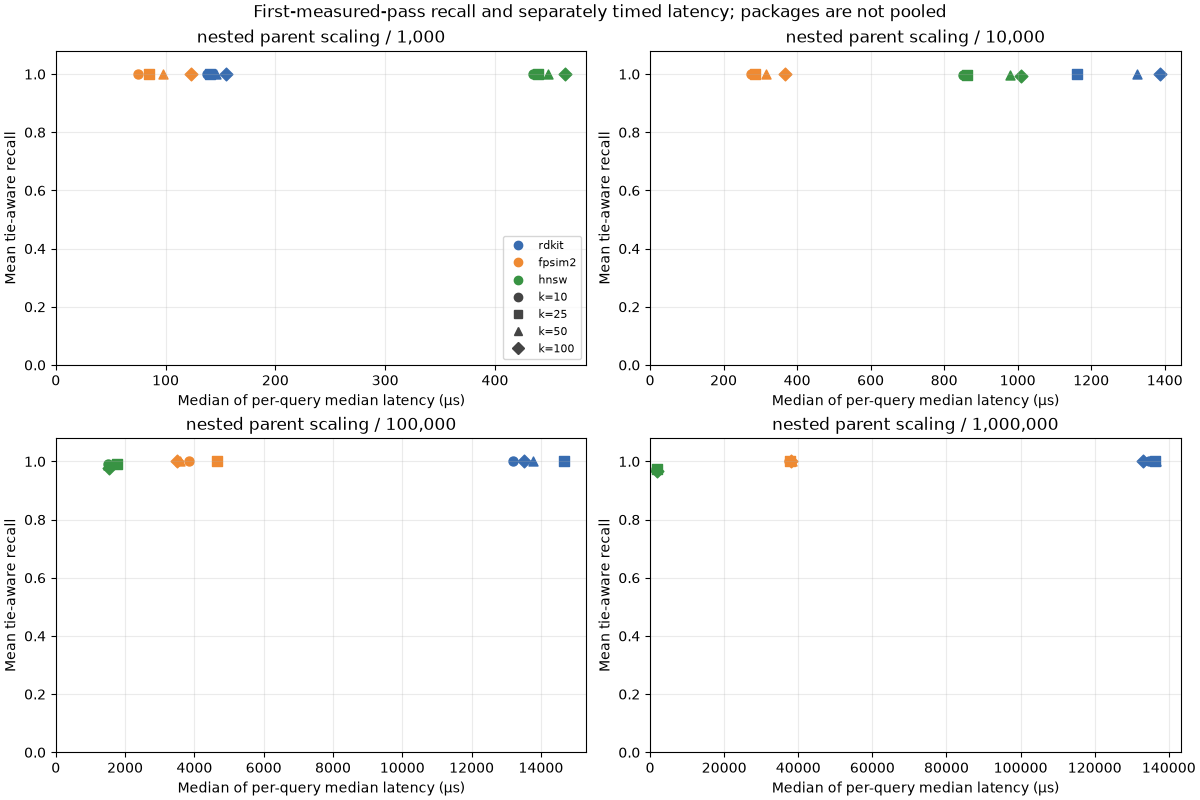

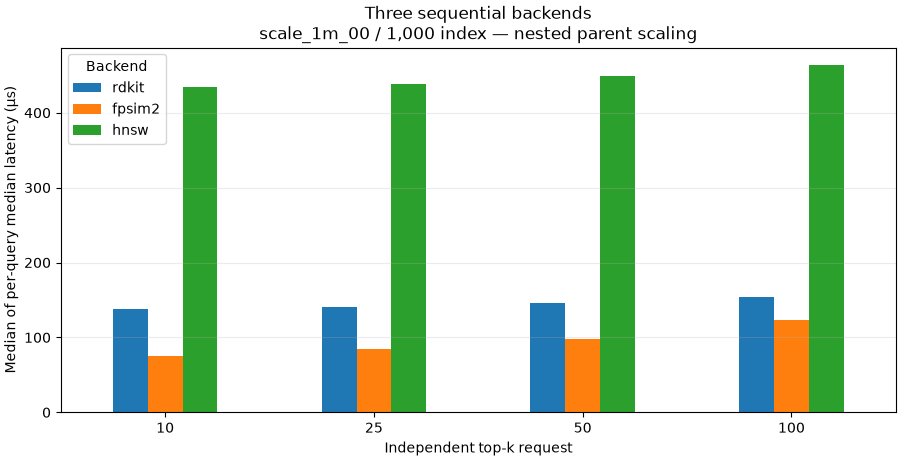

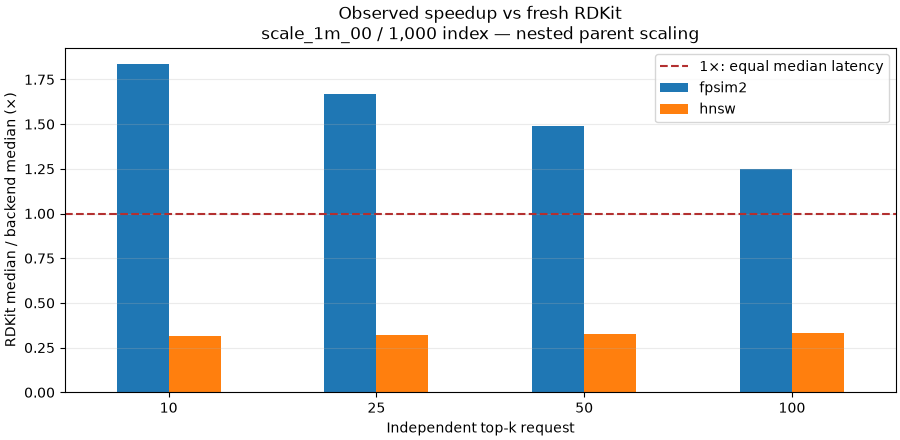

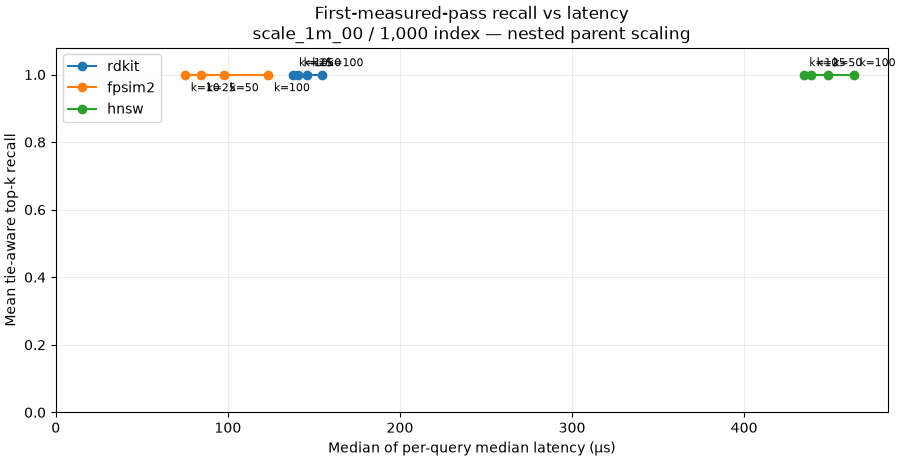

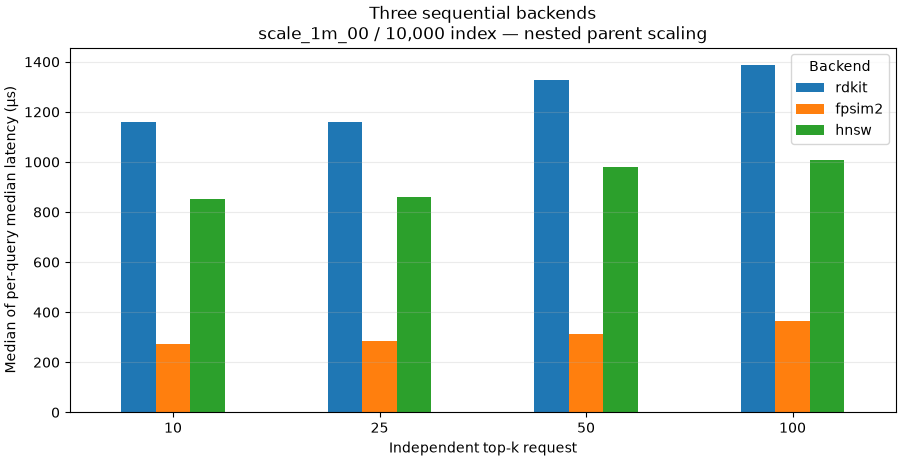

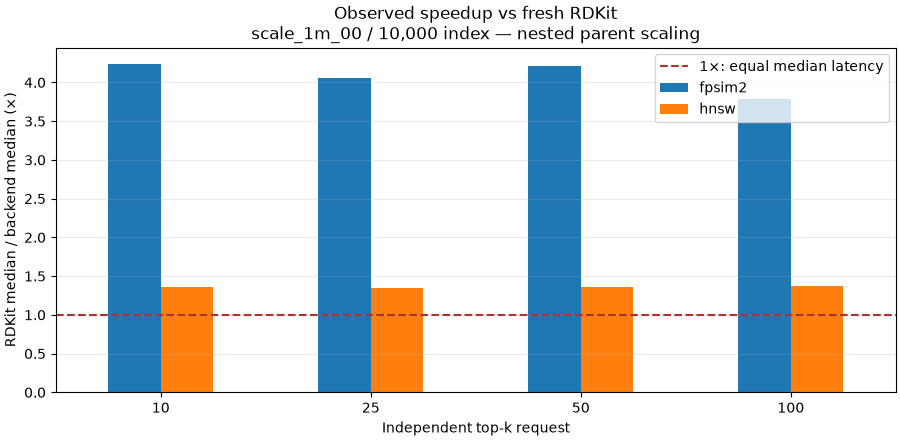

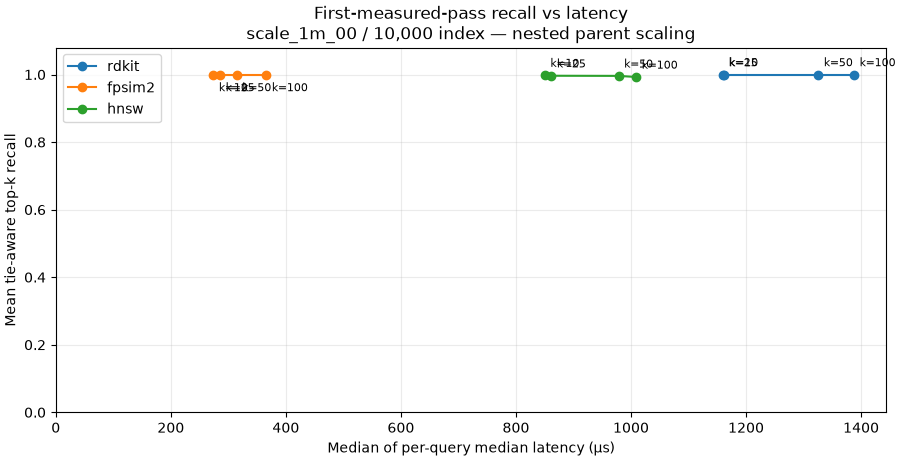

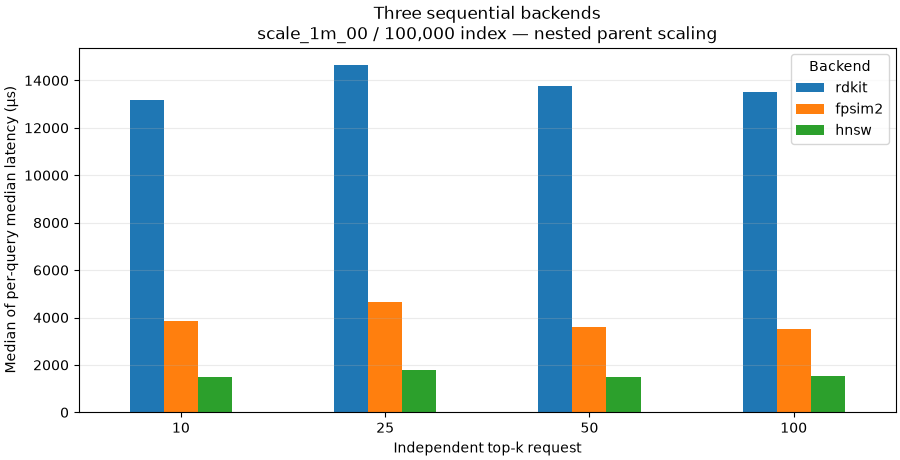

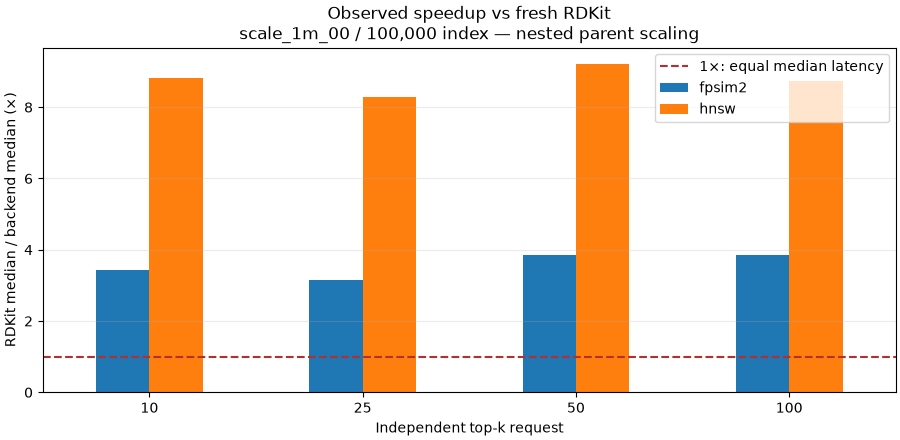

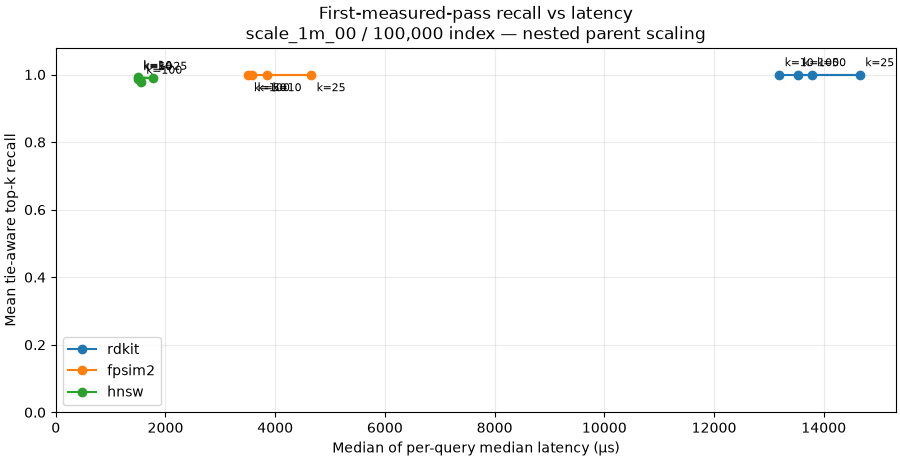

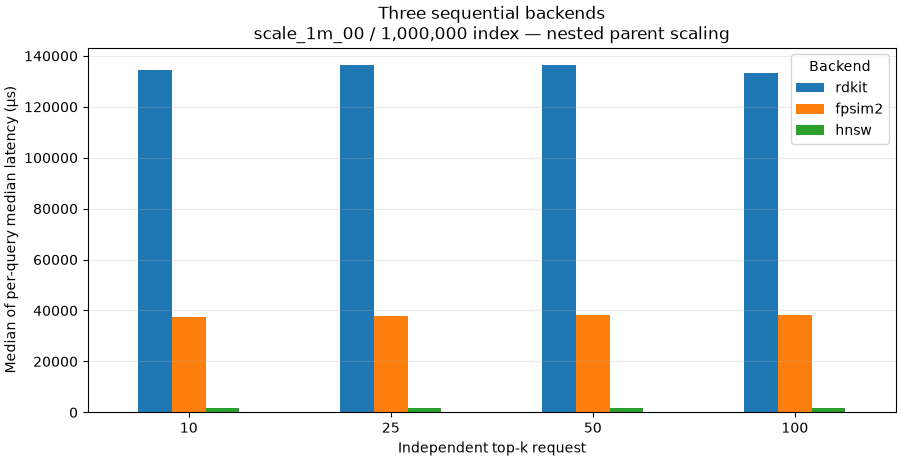

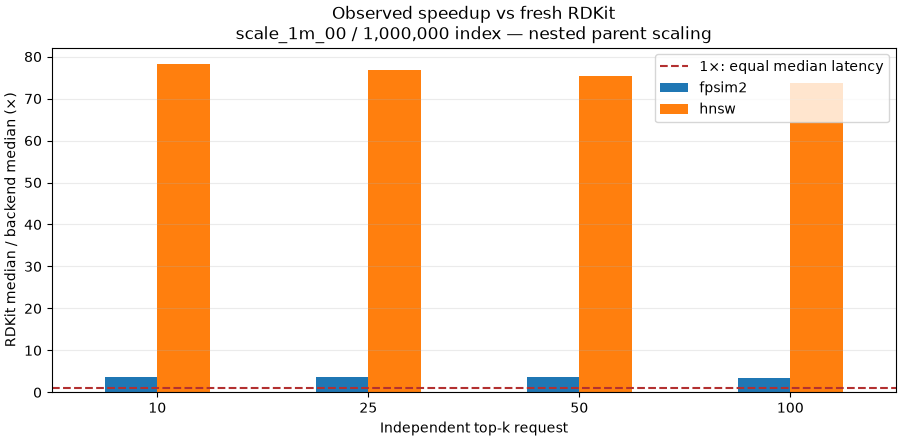

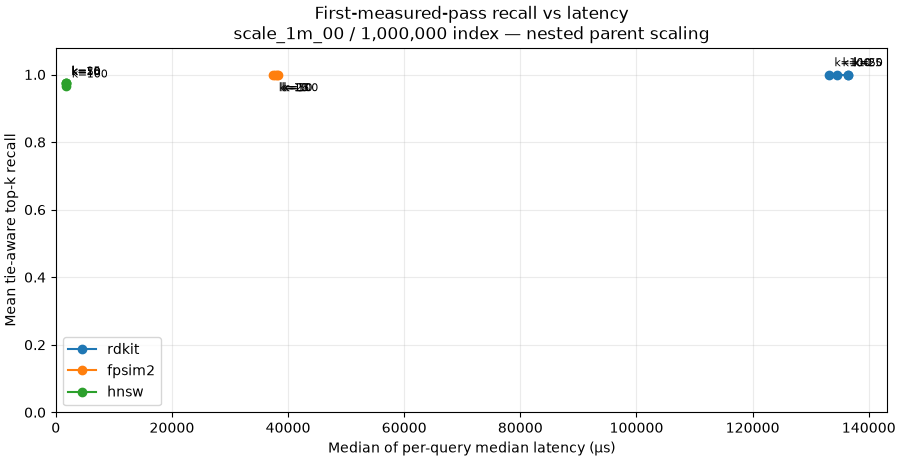

In [7]:
pointer = read_json(EXPERIMENT / "latest_report.json")
from chemtellect.fingerprint_store import file_info
REPORT = ROOT / pointer["path"]
assert file_info(REPORT / "manifest.json") == pointer["manifest"]
manifest = read_json(REPORT / "manifest.json")
for name, expected in manifest["files"].items():
    assert file_info(REPORT / name) == expected, name
print("Verified report:", REPORT / "report.md")
display(Markdown("\n".join(line for line in (REPORT / "report.md").read_text().splitlines() if not line.startswith("!["))))
for image_path in sorted(REPORT.glob("*.png")):
    display(Image(filename=str(image_path)))
for report in reports:
    run_path = ROOT / state["sizes"][str(report["index_size"])]["path"]
    for name in report["charts"]:
        if name.endswith(".png"):
            display(Image(filename=str(run_path / name)))

## Interpretation and limits
One acquisition, fixed queries, one graph per size, and machine-specific sequential in-memory observations. Threshold recall is top-k limited; empty ground truth is excluded with denominators retained. These measurements support neither a measured 100M claim nor biological validity. Historical acquisitions remain separate. See `docs/dataset_pipeline.md` for execution, resume, and verification commands.